# Drive mount pour les fichers

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

zip_path = Path("/content/drive/MyDrive/SID/PROJET_SID_2026.zip")

print("ZIP found:", zip_path.is_file())

ZIP found: True


In [ ]:
import zipfile
import json

annotation_path = (
    "PROJET_SID_2026/movie/annotation/00203/00203_clip_017.json"
)

with zipfile.ZipFile(zip_path, "r") as archive:
    example = json.loads(archive.read(annotation_path))

print(json.dumps(example, indent=2))

{
  "video_id": "00203_clip_017",
  "brightness": 0.1,
  "colorfulness": 0.8,
  "hue": 222,
  "emotion": "sadness",
  "caption": "The video shows a man with a large afro and a beard, wearing a blue jacket and a plaid shirt. He is surrounded by people, with one person's hand on his shoulder. The background is dark and blurry, with a few lights visible.",
  "duration": 4.25
}


In [ ]:
annotation_paths = []

with zipfile.ZipFile(zip_path, "r") as archive:
    for filename in archive.namelist():
        if (
            filename.startswith("PROJET_SID_2026/movie/annotation/")
            and filename.endswith(".json")
        ):
            annotation_paths.append(filename)

print("Number of annotations:", len(annotation_paths))
print("First annotation:", annotation_paths[0])

Number of annotations: 3088
First annotation: PROJET_SID_2026/movie/annotation/00203/00203_clip_017.json


In [ ]:
import pandas as pd

rows = []

with zipfile.ZipFile(zip_path, "r") as archive:
    for annotation_path in annotation_paths:
        annotation = json.loads(archive.read(annotation_path))

        # Keep the film ID
        annotation["film_id"] = annotation["video_id"].split("_clip_")[0]

        rows.append(annotation)

df = pd.DataFrame(rows)

print("Table dimensions:", df.shape)
df.head()

Table dimensions: (3088, 8)


,video_id,brightness,colorfulness,hue,emotion,caption,duration,film_id
0,00203_clip_017,0.1,0.8,222,sadness,The video shows a man with a large afro and a ...,4.25,00203
1,00203_clip_026,0.2,0.8,227,amusement,The video captures a lively scene at a nightcl...,6.21,00203
2,00203_clip_030,0.1,0.8,230,amusement,The scene is set in a nightclub with a crowd o...,5.50,00203
3,00203_clip_042,0.2,0.7,223,amusement,The video shows a group of people dancing in a...,4.67,00203
4,00203_clip_003,0.2,0.7,220,amusement,The video shows two men standing in a dimly li...,5.55,00203


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3088 entries, 0 to 3087
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   video_id      3088 non-null   object 
 1   brightness    3088 non-null   float64
 2   colorfulness  3088 non-null   float64
 3   hue           3088 non-null   int64  
 4   emotion       3088 non-null   object 
 5   caption       3088 non-null   object 
 6   duration      3088 non-null   float64
 7   film_id       3088 non-null   object 
dtypes: float64(3), int64(1), object(4)
memory usage: 193.1+ KB


In [ ]:
df.isna().sum()

,0
video_id,0
brightness,0
colorfulness,0
hue,0
emotion,0
caption,0
duration,0
film_id,0


In [ ]:
print("Nombre de films:", df["film_id"].nunique())

print("Duplicat IDs:", df["video_id"].duplicated().sum())

Nombre de films: 350
Duplicat IDs: 0


In [ ]:
emotion_counts = df["emotion"].value_counts()

print(emotion_counts)

emotion
anger          677
fear           519
contentment    373
excitement     354
sadness        338
disgust        297
awe            286
amusement      244
Name: count, dtype: int64


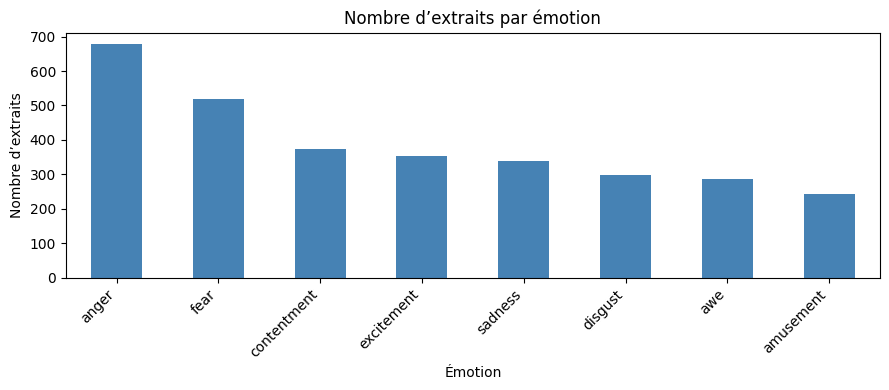

In [ ]:
import matplotlib.pyplot as plt

nombre_extraits_par_emotion = df["emotion"].value_counts()

nombre_extraits_par_emotion.plot(
    kind="bar",
    figsize=(9, 4),
    color="steelblue"
)

plt.title("Nombre d’extraits par émotion")
plt.xlabel("Émotion")
plt.ylabel("Nombre d’extraits")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Les huit classes d’émotions sont présentes, mais leurs effectifs sont déséquilibrés. La classe « anger » contient 677 extraits, contre 244 pour « amusement », soit environ 2,8 fois plus. Ce déséquilibre devra être pris en compte lors de l’évaluation des modèles.

In [ ]:
statistiques_duree = df["duration"].describe()

print(statistiques_duree)

count    3088.000000
mean        8.141580
std         4.737166
min         4.000000
25%         4.960000
50%         6.420000
75%         9.432500
max        29.820000
Name: duration, dtype: float64


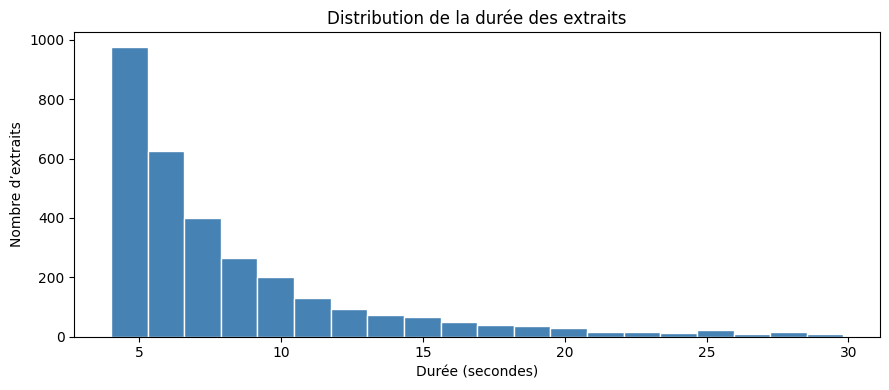

In [ ]:
import matplotlib.pyplot as plt

df["duration"].plot(
    kind="hist",
    bins=20,
    figsize=(9, 4),
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution de la durée des extraits")
plt.xlabel("Durée (secondes)")
plt.ylabel("Nombre d’extraits")
plt.tight_layout()
plt.show()

La majorité des extraits sont courts : la durée médiane est de 6,42 secondes et environ 75 % des extraits durent au plus 9,43 secondes. La distribution présente une asymétrie à droite, avec quelques extraits plus longs, jusqu’à 29,82 secondes.

In [ ]:
nombre_extraits_par_film = df.groupby("film_id").size()

print(nombre_extraits_par_film.describe())

count    350.000000
mean       8.822857
std        3.428775
min        2.000000
25%        6.000000
50%        8.000000
75%       11.000000
max       22.000000
dtype: float64


La majorité des extraits sont courts : la durée médiane est de 6,42 secondes et environ 75 % des extraits durent au plus 9,43 secondes. La distribution présente une asymétrie à droite, avec quelques extraits plus longs, jusqu’à 29,82 secondes.

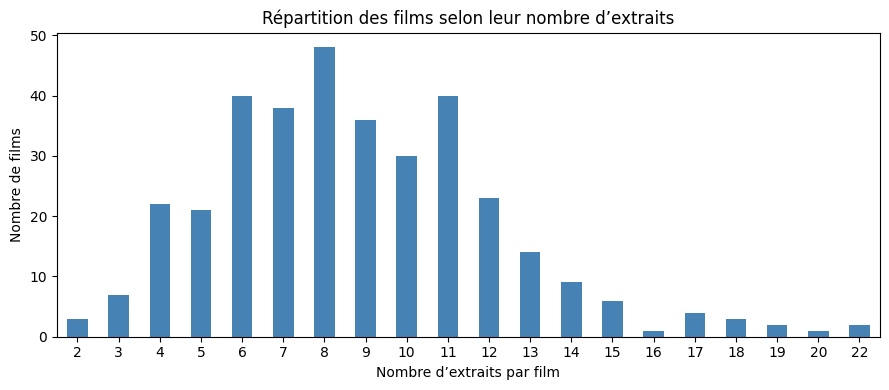

In [ ]:
repartition_films = nombre_extraits_par_film.value_counts().sort_index()

repartition_films.plot(
    kind="bar",
    figsize=(9, 4),
    color="steelblue"
)

plt.title("Répartition des films selon leur nombre d’extraits")
plt.xlabel("Nombre d’extraits par film")
plt.ylabel("Nombre de films")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
nombre_films_par_emotion = (
    df.groupby("emotion")["film_id"]
    .nunique()
    .sort_values(ascending=False)
)

print(nombre_films_par_emotion)

emotion
anger          223
fear           171
excitement     151
disgust        146
contentment    140
sadness        133
awe            120
amusement       96
Name: film_id, dtype: int64


Les émotions sont également réparties de manière inégale entre les films. La classe « anger » apparaît dans 223 films, contre 96 pour « amusement ». Un même film pouvant contenir plusieurs émotions, ces effectifs ne doivent pas être additionnés pour obtenir le nombre total de films.

In [ ]:
tableau_films_emotions = pd.crosstab(
    df["film_id"],
    df["emotion"]
)

tableau_films_emotions.head()

emotion,amusement,anger,awe,contentment,disgust,excitement,fear,sadness
film_id,,,,,,,,
00000,0,11,0,1,1,1,3,0
00002,0,10,1,2,0,1,0,0
00003,1,4,0,0,2,0,0,1
00004,0,3,0,0,0,0,3,5
00005,2,2,1,0,0,2,0,4


In [ ]:
proportions_globales = df["emotion"].value_counts(normalize=True)

print("Proportion de chaque émotion dans le jeu de données (%) :")
print((proportions_globales * 100).round(2))

Proportion de chaque émotion dans le jeu de données (%) :
emotion
anger          21.92
fear           16.81
contentment    12.08
excitement     11.46
sadness        10.95
disgust         9.62
awe             9.26
amusement       7.90
Name: proportion, dtype: float64


In [ ]:
# Mélanger les films de manière reproductible
films_melanges = tableau_films_emotions.sample(
    frac=1,
    random_state=42
).index

# Répartir les identifiants des films
films_apprentissage = films_melanges[:250]
films_developpement = films_melanges[250:300]
films_test = films_melanges[300:]

print("Films d’apprentissage :", len(films_apprentissage))
print("Films de développement :", len(films_developpement))
print("Films de test :", len(films_test))

Films d’apprentissage : 250
Films de développement : 50
Films de test : 50


In [ ]:
# Sélectionner les extraits appartenant aux films de chaque ensemble
donnees_apprentissage = df[
    df["film_id"].isin(films_apprentissage)
].copy()

donnees_developpement = df[
    df["film_id"].isin(films_developpement)
].copy()

donnees_test = df[
    df["film_id"].isin(films_test)
].copy()

print("Extraits d’apprentissage :", len(donnees_apprentissage))
print("Extraits de développement :", len(donnees_developpement))
print("Extraits de test :", len(donnees_test))

Extraits d’apprentissage : 2212
Extraits de développement : 472
Extraits de test : 404


In [ ]:
# Comparer les proportions des émotions dans les trois ensembles
comparaison_proportions = pd.DataFrame({
    "Global": proportions_globales,
    "Apprentissage": donnees_apprentissage["emotion"].value_counts(
        normalize=True
    ),
    "Développement": donnees_developpement["emotion"].value_counts(
        normalize=True
    ),
    "Test": donnees_test["emotion"].value_counts(normalize=True)
}).fillna(0)

# Afficher les proportions en pourcentage
(comparaison_proportions * 100).round(2)

,Global,Apprentissage,Développement,Test
emotion,,,,
amusement,7.90,7.55,9.53,7.92
anger,21.92,23.24,17.80,19.55
awe,9.26,8.50,14.83,6.93
contentment,12.08,10.85,18.01,11.88
disgust,9.62,10.22,9.11,6.93
excitement,11.46,11.44,10.81,12.38
fear,16.81,16.77,12.08,22.52
sadness,10.95,11.44,7.84,11.88


In [ ]:
# Calculer les écarts absolus par rapport aux proportions globales
ecarts_absolus = (
    comparaison_proportions
    .drop(columns="Global")
    .sub(comparaison_proportions["Global"], axis="index")
    .abs()
    * 100
)

# Calculer la moyenne des écarts sur les émotions et les ensembles
score_repartition = ecarts_absolus.mean().mean()

print(
    "Écart moyen aux proportions globales :",
    round(score_repartition, 2),
    "points de pourcentage"
)

ecarts_absolus.round(2)

Écart moyen aux proportions globales : 1.93 points de pourcentage


,Apprentissage,Développement,Test
emotion,,,
amusement,0.35,1.63,0.02
anger,1.31,4.13,2.37
awe,0.76,5.57,2.33
contentment,1.23,5.93,0.20
disgust,0.60,0.51,2.69
excitement,0.03,0.66,0.91
fear,0.03,4.73,5.72
sadness,0.49,3.11,0.94


In [ ]:
def evaluer_repartition(graine):
    # Mélanger les films puis constituer les trois ensembles
    films = tableau_films_emotions.sample(
        frac=1, random_state=graine
    ).index

    ensembles = {
        "Apprentissage": films[:250],
        "Développement": films[250:300],
        "Test": films[300:]
    }

    proportions = pd.DataFrame({"Global": proportions_globales})

    for nom, identifiants in ensembles.items():
        # Additionner les effectifs de chaque émotion pour ces films
        effectifs = tableau_films_emotions.loc[identifiants].sum()

        # Écarter une répartition si une émotion est absente
        if (effectifs == 0).any():
            return float("inf")

        proportions[nom] = effectifs / effectifs.sum()

    ecarts = (
        proportions.drop(columns="Global")
        .sub(proportions["Global"], axis="index")
        .abs()
    )

    return ecarts.mean().mean() * 100

In [ ]:
score_verification = evaluer_repartition(42)

print("Score de vérification :", round(score_verification, 2))

Score de vérification : 1.93


In [ ]:
resultats_repartitions = []

# Comparer les répartitions obtenues avec les graines
for graine in range(10000):
    score = evaluer_repartition(graine)

    resultats_repartitions.append({
        "Graine": graine,
        "Écart moyen (points)": score
    })

# Classer les candidats du plus faible écart au plus élevé
classement_repartitions = (
    pd.DataFrame(resultats_repartitions)
    .sort_values("Écart moyen (points)")
    .reset_index(drop=True)
)

classement_repartitions.head(5).round(3)

,Graine,Écart moyen (points)
0,9125,0.581
1,4114,0.624
2,9837,0.646
3,5806,0.666
4,9543,0.686


In [ ]:
# Récupérer la graine du candidat le mieux classé
meilleure_graine = int(classement_repartitions.iloc[0]["Graine"])

films_candidats = tableau_films_emotions.sample(
    frac=1,
    random_state=meilleure_graine
).index

ensembles_candidats = {
    "Apprentissage": films_candidats[:250],
    "Développement": films_candidats[250:300],
    "Test": films_candidats[300:]
}

# Calculer les proportions pour ce candidat
comparaison_candidat = pd.DataFrame({
    "Global": proportions_globales
})

for nom, identifiants in ensembles_candidats.items():
    effectifs = tableau_films_emotions.loc[identifiants].sum()
    comparaison_candidat[nom] = effectifs / effectifs.sum()

print("Graine du candidat :", meilleure_graine)
(comparaison_candidat * 100).round(2)

Graine du candidat : 9125


,Global,Apprentissage,Développement,Test
emotion,,,,
anger,21.92,21.66,23.34,21.76
fear,16.81,16.60,16.06,18.91
contentment,12.08,12.08,12.63,11.40
excitement,11.46,11.86,11.13,9.59
sadness,10.95,10.69,11.56,11.66
disgust,9.62,9.62,9.85,9.33
awe,9.26,9.53,7.49,9.84
amusement,7.90,7.96,7.92,7.51


Parmi les 10 000 répartitions évaluées, la graine 9125 présente le plus faible écart moyen aux proportions globales, soit environ 0,58 point de pourcentage. Cette répartition constitue une proposition provisoire qui sera discutée avec l’enseignant avant toute validation définitive.

In [ ]:
# Convertir les listes d’identifiants en ensembles
films_apprentissage_candidat = set(ensembles_candidats["Apprentissage"])
films_developpement_candidat = set(ensembles_candidats["Développement"])
films_test_candidat = set(ensembles_candidats["Test"])

# Vérifier les intersections entre les ensembles
print("Films communs apprentissage / développement :",
      len(films_apprentissage_candidat & films_developpement_candidat))

print("Films communs apprentissage / test :",
      len(films_apprentissage_candidat & films_test_candidat))

print("Films communs développement / test :",
      len(films_developpement_candidat & films_test_candidat))

# Vérifier que tous les films sont couverts
films_couverts = (
    films_apprentissage_candidat
    | films_developpement_candidat
    | films_test_candidat
)

print("Tous les films sont présents :",
      films_couverts == set(df["film_id"]))

Films communs apprentissage / développement : 0
Films communs apprentissage / test : 0
Films communs développement / test : 0
Tous les films sont présents : True


In [ ]:
# Compter les extraits par émotion pour le candidat provisoire
effectifs_candidat = pd.DataFrame()

for nom, identifiants in ensembles_candidats.items():
    effectifs_candidat[nom] = (
        tableau_films_emotions.loc[identifiants].sum()
    )

print("Nombre d’extraits par ensemble :")
print(effectifs_candidat.sum())

effectifs_candidat

Nombre d’extraits par ensemble :
Apprentissage    2235
Développement     467
Test              386
dtype: int64


,Apprentissage,Développement,Test
emotion,,,
amusement,178,37,29
anger,484,109,84
awe,213,35,38
contentment,270,59,44
disgust,215,46,36
excitement,265,52,37
fear,371,75,73
sadness,239,54,45


Nous avons comparé 10 000 répartitions aléatoires reproductibles, en conservant tous les extraits d’un même film dans un seul ensemble. Chaque répartition comprend 250 films d’apprentissage, 50 de développement et 50 de test.
Parmi les candidats évalués, la graine 9125 minimise l’écart moyen absolu aux proportions globales des émotions, avec environ 0,58 point de pourcentage. L’écart maximal est d’environ 2,10 points.
Les huit émotions sont présentes dans chaque ensemble. Aucun film n’est partagé entre les ensembles et les 3 088 extraits sont conservés. Les effectifs sont de 2 235 extraits pour l’apprentissage, 467 pour le développement et 386 pour le test.
Cette proposition sera discutée avec l’enseignant avant validation définitive.

In [ ]:
# Vérifier les durées et les descriptions textuelles
nombre_durees_invalides = (df["duration"] <= 0).sum()

descriptions_nettoyees = df["caption"].str.strip()

nombre_descriptions_vides = (descriptions_nettoyees == "").sum()
nombre_descriptions_repetees = descriptions_nettoyees.duplicated().sum()

print("Durées nulles ou négatives :", nombre_durees_invalides)
print("Descriptions vides :", nombre_descriptions_vides)
print("Descriptions répétées après leur première occurrence :",
      nombre_descriptions_repetees)

Durées nulles ou négatives : 0
Descriptions vides : 0
Descriptions répétées après leur première occurrence : 4


In [ ]:
# Repérer toutes les occurrences des descriptions répétées
masque_descriptions_repetees = descriptions_nettoyees.duplicated(
    keep=False
)

# Afficher les extraits concernés, regroupés par description
extraits_descriptions_repetees = df.loc[
    masque_descriptions_repetees,
    ["video_id", "film_id", "emotion", "caption"]
].sort_values("caption")

print("Nombre d’extraits concernés :",
      len(extraits_descriptions_repetees))

extraits_descriptions_repetees

Nombre d’extraits concernés : 8


,video_id,film_id,emotion,caption
2643,00351_clip_009,00351,awe,The video depicts a group of people gathered i...
2648,00351_clip_010,00351,awe,The video depicts a group of people gathered i...
914,00132_clip_016,00132,sadness,The video shows a man standing on a balcony of...
918,00132_clip_019,00132,sadness,The video shows a man standing on a balcony of...
1915,00230_clip_015,00230,sadness,The video shows a man with short brown hair we...
1916,00230_clip_019,00230,disgust,The video shows a man with short brown hair we...
2479,00361_clip_039,00361,excitement,The video shows two men in a room with a windo...
2482,00361_clip_037,00361,excitement,The video shows two men in a room with a windo...


In [ ]:
# Lire la liste des fichiers présents dans le ZIP
with zipfile.ZipFile(zip_path, "r") as archive:
    fichiers_zip = set(archive.namelist())

audios_manquants = []
videos_manquantes = []

for chemin_annotation in annotation_paths:
    # Construire les chemins attendus à partir du chemin du JSON
    chemin_audio = chemin_annotation.replace(
        "/annotation/", "/audio/"
    ).replace(".json", ".mp3")

    chemin_video = chemin_annotation.replace(
        "/annotation/", "/video/"
    ).replace(".json", ".mp4")

    if chemin_audio not in fichiers_zip:
        audios_manquants.append(chemin_audio)

    if chemin_video not in fichiers_zip:
        videos_manquantes.append(chemin_video)

print("Fichiers audio manquants :", len(audios_manquants))
print("Fichiers vidéo manquants :", len(videos_manquantes))

Fichiers audio manquants : 0
Fichiers vidéo manquants : 0


Les 3 088 annotations disposent chacune d’un fichier audio MP3 et d’un fichier vidéo MP4 correspondant. Aucun fichier associé n’est manquant dans le ZIP. Cette vérification porte sur leur présence, pas encore sur leur lisibilité.

In [ ]:
# Résumer les durées pour chaque émotion
durees_par_emotion = df.groupby("emotion").agg(
    duree_moyenne_s=("duration", "mean"),
    duree_mediane_s=("duration", "median"),
    duree_totale_s=("duration", "sum")
)

durees_par_emotion.round(2)

,duree_moyenne_s,duree_mediane_s,duree_totale_s
emotion,,,
amusement,7.86,6.51,1918.03
anger,7.69,6.05,5208.83
awe,8.17,6.36,2336.25
contentment,8.39,6.84,3128.16
disgust,8.10,6.71,2406.10
excitement,8.18,6.42,2895.06
fear,8.05,6.34,4175.38
sadness,9.09,6.88,3073.39


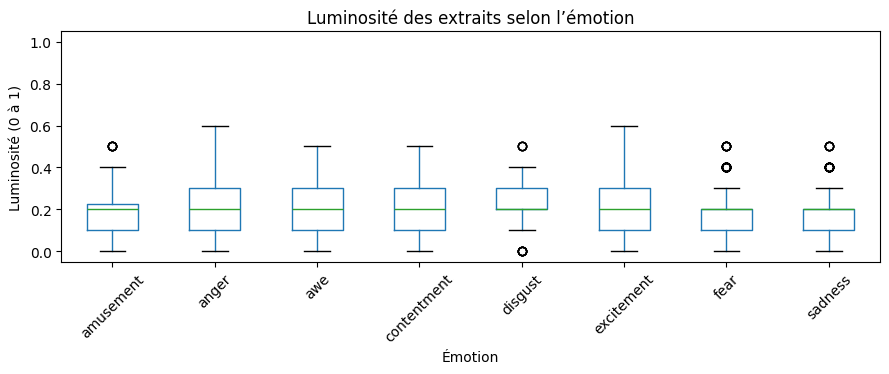

In [ ]:
import matplotlib.pyplot as plt

df.boxplot(
    column="brightness",
    by="emotion",
    figsize=(9, 4),
    grid=False,
    rot=45
)

plt.suptitle("")
plt.title("Luminosité des extraits selon l’émotion")
plt.xlabel("Émotion")
plt.ylabel("Luminosité (0 à 1)")
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

Les médianes de luminosité sont proches de 0,2 pour les huit émotions. Les distributions présentent un recouvrement important, malgré quelques différences de dispersion. La luminosité seule ne montre donc pas de séparation visuelle nette entre les classes.

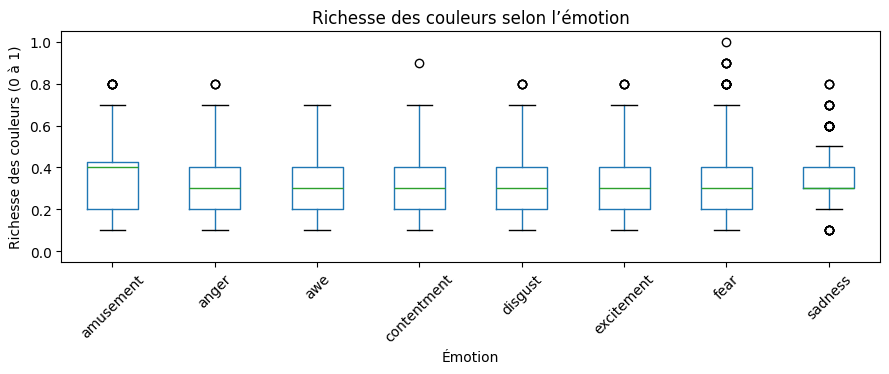

In [ ]:
df.boxplot(
    column="colorfulness",
    by="emotion",
    figsize=(9, 4),
    grid=False,
    rot=45
)

plt.suptitle("")
plt.title("Richesse des couleurs selon l’émotion")
plt.xlabel("Émotion")
plt.ylabel("Richesse des couleurs (0 à 1)")
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

La classe « amusement » présente une médiane de richesse des couleurs plus élevée, proche de 0,4 contre environ 0,3 pour les autres classes. Cependant, les distributions se recouvrent largement. Cette différence descriptive ne suffit pas à distinguer clairement les huit émotions.

In [ ]:
# Compter le nombre d’extraits pour chaque film
nombre_extraits_par_film = df.groupby("film_id").size()

# Afficher les statistiques descriptives
print("Nombre de films :", len(nombre_extraits_par_film))
print("Nombre minimum d’extraits par film :", nombre_extraits_par_film.min())
print("Nombre maximum d’extraits par film :", nombre_extraits_par_film.max())

print(
    "Nombre moyen d’extraits par film :",
    round(nombre_extraits_par_film.mean(), 2)
)

print(
    "Nombre médian d’extraits par film :",
    nombre_extraits_par_film.median()
)

Nombre de films : 350
Nombre minimum d’extraits par film : 2
Nombre maximum d’extraits par film : 22
Nombre moyen d’extraits par film : 8.82
Nombre médian d’extraits par film : 8.0


In [ ]:
bilan_tailles = []

for nom, identifiants in ensembles_candidats.items():
    nombre_observe = effectifs_candidat[nom].sum()

    # Effectif attendu si les extraits suivent les proportions de films
    nombre_reference = len(df) * len(identifiants) / df["film_id"].nunique()

    ecart_relatif = (
        (nombre_observe - nombre_reference) / nombre_reference * 100
    )

    bilan_tailles.append({
        "Ensemble": nom,
        "Nombre de films": len(identifiants),
        "Extraits observés": nombre_observe,
        "Extraits de référence": nombre_reference,
        "Écart relatif (%)": ecart_relatif
    })

pd.DataFrame(bilan_tailles).round(2)

,Ensemble,Nombre de films,Extraits observés,Extraits de référence,Écart relatif (%)
0,Apprentissage,250,2235,2205.71,1.33
1,Développement,50,467,441.14,5.86
2,Test,50,386,441.14,-12.50


In [ ]:
# Compter les extraits de chaque film
nombre_extraits_par_film = tableau_films_emotions.sum(axis=1)

ecarts_maximaux_effectifs = []

# Examiner les mêmes candidats que dans la recherche précédente
for graine in classement_repartitions["Graine"]:
    films_essai = tableau_films_emotions.sample(
        frac=1,
        random_state=int(graine)
    ).index

    groupes_essai = [
        films_essai[:250],
        films_essai[250:300],
        films_essai[300:]
    ]

    ecarts_effectifs = []

    for groupe in groupes_essai:
        nombre_observe = nombre_extraits_par_film.loc[groupe].sum()
        nombre_reference = len(df) * len(groupe) / len(tableau_films_emotions)

        ecart_relatif = (
            abs(nombre_observe - nombre_reference)
            / nombre_reference * 100
        )

        ecarts_effectifs.append(ecart_relatif)

    ecarts_maximaux_effectifs.append(max(ecarts_effectifs))

# Conserver les deux critères pour chaque candidat
classement_avec_tailles = classement_repartitions.copy()

classement_avec_tailles["Écart maximal des effectifs (%)"] = (
    ecarts_maximaux_effectifs
)

# Priorité : rester très proche du meilleur équilibre des émotions
marge_emotions_points = 0.05

meilleur_score_emotions = classement_avec_tailles[
    "Écart moyen (points)"
].min()

candidats_proches = classement_avec_tailles[
    classement_avec_tailles["Écart moyen (points)"]
    <= meilleur_score_emotions + marge_emotions_points
].copy()

# Critère secondaire : équilibrer les effectifs parmi ces candidats
classement_secondaire = (
    candidats_proches
    .sort_values([
        "Écart maximal des effectifs (%)",
        "Écart moyen (points)"
    ])
    .reset_index(drop=True)
)

print("Nombre de candidats retenus :", len(classement_secondaire))

classement_secondaire.head(10).round(3)

Nombre de candidats retenus : 2


,Graine,Écart moyen (points),Écart maximal des effectifs (%)
0,4114,0.624,5.635
1,9125,0.581,12.500


In [ ]:
bilan_deux_candidats = []

for graine in [4114, 9125]:
    films = tableau_films_emotions.sample(
        frac=1, random_state=graine
    ).index

    ensembles_a_comparer = {
        "Apprentissage": films[:250],
        "Développement": films[250:300],
        "Test": films[300:]
    }

    for nom, identifiants in ensembles_a_comparer.items():
        # Compter les extraits et calculer les proportions des émotions
        effectifs = tableau_films_emotions.loc[identifiants].sum()
        nombre_extraits = effectifs.sum()
        proportions = effectifs / nombre_extraits

        ecarts_emotions = (
            (proportions - proportions_globales).abs() * 100
        )

        # Comparer le nombre d’extraits à sa référence
        effectif_reference = (
            len(df) * len(identifiants) / len(tableau_films_emotions)
        )

        ecart_effectif = (
            (nombre_extraits - effectif_reference)
            / effectif_reference * 100
        )

        bilan_deux_candidats.append({
            "Graine": graine,
            "Ensemble": nom,
            "Films": len(identifiants),
            "Extraits": nombre_extraits,
            "Écart effectif (%)": ecart_effectif,
            "Écart maximal émotions (points)": ecarts_emotions.max()
        })

pd.DataFrame(bilan_deux_candidats).round(3)

,Graine,Ensemble,Films,Extraits,Écart effectif (%),Écart maximal émotions (points)
0,4114,Apprentissage,250,2168,-1.710,0.444
1,4114,Développement,50,454,2.915,1.388
2,4114,Test,50,466,5.635,1.683
3,9125,Apprentissage,250,2235,1.328,0.393
4,9125,Développement,50,467,5.861,1.767
5,9125,Test,50,386,-12.500,2.105


La graine 9125 présente le plus faible écart moyen aux proportions globales des émotions : 0,581 point, contre 0,624 pour la graine 4114. La différence de 0,043 point respecte la marge de tolérance provisoire fixée à 0,05 point.
La graine 4114 permet cependant une répartition plus équilibrée du nombre d’extraits, avec 2 168 extraits d’apprentissage, 454 de développement et 466 de test. Son écart maximal relatif aux effectifs de référence est de 5,635 %, contre 12,5 % pour la graine 9125.
Elle présente également des écarts maximaux de proportions d’émotions plus faibles en développement et en test. Elle constitue donc un compromis à proposer à l’enseignant, en conservant l’équilibre des émotions comme critère principal et celui des effectifs comme critère secondaire.

In [ ]:
# Retenir la répartition proposée par notre groupe
graine_proposee = 4114

films_proposes = tableau_films_emotions.sample(
    frac=1,
    random_state=graine_proposee
).index

ensembles_proposes = {
    "Apprentissage": films_proposes[:250],
    "Développement": films_proposes[250:300],
    "Test": films_proposes[300:]
}

# Afficher les effectifs de la proposition
for nom, identifiants in ensembles_proposes.items():
    nombre_extraits = (
        tableau_films_emotions.loc[identifiants].sum().sum()
    )

    print(nom, ":", len(identifiants),
          "films et", nombre_extraits, "extraits")

Apprentissage : 250 films et 2168 extraits
Développement : 50 films et 454 extraits
Test : 50 films et 466 extraits


In [ ]:
# Compter les extraits par émotion dans la proposition retenue
effectifs_proposition = pd.DataFrame({
    "Global": tableau_films_emotions.sum()
})

for nom, identifiants in ensembles_proposes.items():
    effectifs_proposition[nom] = (
        tableau_films_emotions.loc[identifiants].sum()
    )

effectifs_proposition

,Global,Apprentissage,Développement,Test
emotion,,,,
amusement,244,170,42,32
anger,677,482,100,95
awe,286,199,36,51
contentment,373,263,55,55
disgust,297,206,48,43
excitement,354,241,52,61
fear,519,374,70,75
sadness,338,233,51,54


In [ ]:
# Calculer les pourcentages à l’intérieur de chaque ensemble
proportions_proposition = effectifs_proposition.div(
    effectifs_proposition.sum(),
    axis="columns"
) * 100

proportions_proposition.round(2)

,Global,Apprentissage,Développement,Test
emotion,,,,
amusement,7.90,7.84,9.25,6.87
anger,21.92,22.23,22.03,20.39
awe,9.26,9.18,7.93,10.94
contentment,12.08,12.13,12.11,11.80
disgust,9.62,9.50,10.57,9.23
excitement,11.46,11.12,11.45,13.09
fear,16.81,17.25,15.42,16.09
sadness,10.95,10.75,11.23,11.59


In [ ]:
nombre_essais = 50000
resultats_repartitions = []

# Évaluer les graines de 0 à 49 999
for graine in range(nombre_essais):
    score = evaluer_repartition(graine)

    resultats_repartitions.append({
        "Graine": graine,
        "Écart moyen (points)": score
    })

classement_repartitions = (
    pd.DataFrame(resultats_repartitions)
    .sort_values("Écart moyen (points)")
    .reset_index(drop=True)
)

classement_repartitions.head(5).round(3)

,Graine,Écart moyen (points)
0,17630,0.503
1,22558,0.550
2,29971,0.556
3,28663,0.577
4,9125,0.581


In [ ]:
# Vérifier que la recherche sur 50 000 graines a été exécutée
assert len(classement_repartitions) == 50000, (
    "Exécuter d’abord la recherche sur 50 000 graines."
)

# Retenir les candidats proches du meilleur équilibre des émotions
marge_emotions_points = 0.05
meilleur_score = classement_repartitions["Écart moyen (points)"].min()

candidats_admissibles = classement_repartitions[
    classement_repartitions["Écart moyen (points)"]
    <= meilleur_score + marge_emotions_points
].copy()

ecarts_maximaux = []

# Calculer le critère secondaire pour ces candidats
for graine in candidats_admissibles["Graine"]:
    films = tableau_films_emotions.sample(
        frac=1, random_state=int(graine)
    ).index

    groupes = [films[:250], films[250:300], films[300:]]
    ecarts = []

    for identifiants in groupes:
        effectif_observe = (
            tableau_films_emotions.loc[identifiants].sum().sum()
        )

        effectif_reference = (
            len(df) * len(identifiants) / len(tableau_films_emotions)
        )

        ecarts.append(
            abs(effectif_observe - effectif_reference)
            / effectif_reference * 100
        )

    ecarts_maximaux.append(max(ecarts))

candidats_admissibles["Écart maximal des effectifs (%)"] = ecarts_maximaux

# Départager les candidats admissibles grâce aux effectifs
classement_final = (
    candidats_admissibles
    .sort_values([
        "Écart maximal des effectifs (%)",
        "Écart moyen (points)"
    ])
    .reset_index(drop=True)
)

classement_final.round(3)

,Graine,Écart moyen (points),Écart maximal des effectifs (%)
0,22558,0.550,2.234
1,17630,0.503,6.995


In [ ]:
from IPython.display import display

def afficher_repartition(graine):
    films = tableau_films_emotions.sample(
        frac=1, random_state=graine
    ).index

    ensembles = {
        "Apprentissage": films[:250],
        "Développement": films[250:300],
        "Test": films[300:]
    }

    effectifs = pd.DataFrame({
        "Global": tableau_films_emotions.sum()
    })

    print("Graine :", graine)

    for nom, identifiants in ensembles.items():
        effectifs[nom] = tableau_films_emotions.loc[identifiants].sum()

        print(nom, ":", len(identifiants),
              "films et", effectifs[nom].sum(), "extraits")

    print("Effectifs par émotion :")
    display(effectifs)

    pourcentages = effectifs.div(
        effectifs.sum(), axis="columns"
    ) * 100

    print("Répartition des émotions (%) :")
    display(pourcentages.round(2))

In [ ]:
afficher_repartition(22558)

Graine : 22558
Apprentissage : 250 films et 2197 extraits
Développement : 50 films et 451 extraits
Test : 50 films et 440 extraits
Effectifs par émotion :


,Global,Apprentissage,Développement,Test
emotion,,,,
amusement,244,169,40,35
anger,677,478,99,100
awe,286,201,50,35
contentment,373,272,47,54
disgust,297,215,38,44
excitement,354,248,55,51
fear,519,372,71,76
sadness,338,242,51,45


Répartition des émotions (%) :


,Global,Apprentissage,Développement,Test
emotion,,,,
amusement,7.90,7.69,8.87,7.95
anger,21.92,21.76,21.95,22.73
awe,9.26,9.15,11.09,7.95
contentment,12.08,12.38,10.42,12.27
disgust,9.62,9.79,8.43,10.00
excitement,11.46,11.29,12.20,11.59
fear,16.81,16.93,15.74,17.27
sadness,10.95,11.02,11.31,10.23


In [ ]:
afficher_repartition(17630)

Graine : 17630
Apprentissage : 250 films et 2167 extraits
Développement : 50 films et 472 extraits
Test : 50 films et 449 extraits
Effectifs par émotion :


,Global,Apprentissage,Développement,Test
emotion,,,,
amusement,244,176,37,31
anger,677,480,99,98
awe,286,192,47,47
contentment,373,264,56,53
disgust,297,211,44,42
excitement,354,242,62,50
fear,519,370,77,72
sadness,338,232,50,56


Répartition des émotions (%) :


,Global,Apprentissage,Développement,Test
emotion,,,,
amusement,7.90,8.12,7.84,6.90
anger,21.92,22.15,20.97,21.83
awe,9.26,8.86,9.96,10.47
contentment,12.08,12.18,11.86,11.80
disgust,9.62,9.74,9.32,9.35
excitement,11.46,11.17,13.14,11.14
fear,16.81,17.07,16.31,16.04
sadness,10.95,10.71,10.59,12.47


La graine 17630 présente le meilleur équilibre des proportions d’émotions, avec un écart moyen de 0,503 point de pourcentage. La graine 22558 atteint 0,550 point, soit une différence d’environ 0,047 point, inférieure à la marge de tolérance fixée à 0,05 point.
Parmi ces candidats proches sur le critère principal, la graine 22558 présente un meilleur équilibre des effectifs : leur écart relatif maximal aux références est de 2,234 %, contre 6,995 % pour la graine 17630. Elle est donc retenue comme proposition du groupe, avec 2 197 extraits d’apprentissage, 451 de développement et 440 de test. Le choix de la partition commune reste à discuter avec l’enseignant.

In [ ]:
# Retenir la proposition issue de la recherche sur 50 000 graines
graine_proposee = 22558

films_proposes = tableau_films_emotions.sample(
    frac=1, random_state=graine_proposee
).index

ensembles_proposes = {
    "Apprentissage": films_proposes[:250],
    "Développement": films_proposes[250:300],
    "Test": films_proposes[300:]
}

In [ ]:
# Vérifier les nombres de films et d’extraits dans chaque ensemble
for nom, identifiants in ensembles_proposes.items():
    nombre_films = len(identifiants)
    nombre_extraits = df["film_id"].isin(identifiants).sum()

    print(nom, ":", nombre_films, "films et", nombre_extraits, "extraits")

Apprentissage : 250 films et 2197 extraits
Développement : 50 films et 451 extraits
Test : 50 films et 440 extraits
